<a href="https://colab.research.google.com/github/FrankEHA/INGENIERIA_DEL_CONOCIMIENTO/blob/main/EJERCICIO_ADICIONAL_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***Ejercicio 1.1: Exploración del dataset Diabetes***

**Contexto:** antes de entrenar un modelo de regresión (que predice una variable continua) conviene hacer un análisis exploratorio para entender los datos y ver qué variables se relacionan más con lo que queremos predecir.

**Dataset:** load_diabetes() tiene 442 pacientes, 10 features clínicas ya normalizadas (age, sex, bmi, bp y s1 a s6, que son mediciones de suero sanguíneo) y un target continuo: la progresión de la enfermedad un año después.

**Objetivo:** identificar qué features aportan más para predecir la progresión, usando estadísticas, correlación de Pearson y gráficos.

**1. Importar librerías y cargar el dataset como DataFrame**

Se carga load_diabetes() y se convierte a DataFrame, agregando el target como columna.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes

data = load_diabetes()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


**2. Dimensiones, nombres de features y estadísticas descriptivas**

Se revisa el tamaño del dataset (442 muestras, 10 features + target), los nombres de las variables y el resumen estadístico.

In [27]:
print("Dimensiones:", df.shape)
print("Features:", data.feature_names)
print()
df.describe().round(4)

Dimensiones: (442, 11)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']



,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000
mean,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,152.1335
std,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,77.0930
min,-0.1072,-0.0446,-0.0903,-0.1124,-0.1268,-0.1156,-0.1023,-0.0764,-0.1261,-0.1378,25.0000
25%,-0.0373,-0.0446,-0.0342,-0.0367,-0.0342,-0.0304,-0.0351,-0.0395,-0.0332,-0.0332,87.0000
50%,0.0054,-0.0446,-0.0073,-0.0057,-0.0043,-0.0038,-0.0066,-0.0026,-0.0019,-0.0011,140.5000
75%,0.0381,0.0507,0.0312,0.0356,0.0284,0.0298,0.0293,0.0343,0.0324,0.0279,211.5000
max,0.1107,0.0507,0.1706,0.1320,0.1539,0.1988,0.1812,0.1852,0.1336,0.1356,346.0000


**3. Correlación de cada feature con el target**

Se calcula la correlación de Pearson de cada feature con el target y se ordena por valor absoluto.

In [28]:
corr = df.corr()['target'].drop('target')
corr_ordenada = corr.reindex(corr.abs().sort_values(ascending=False).index)
print(corr_ordenada.round(4))

bmi    0.5865
s5     0.5659
bp     0.4415
s4     0.4305
s3    -0.3948
s6     0.3825
s1     0.2120
age    0.1879
s2     0.1741
sex    0.0431
Name: target, dtype: float64


**4. Scatter plots de los 4 features más correlacionados**

Se toman los 4 features con mayor correlación absoluta y se grafica cada uno contra el target.

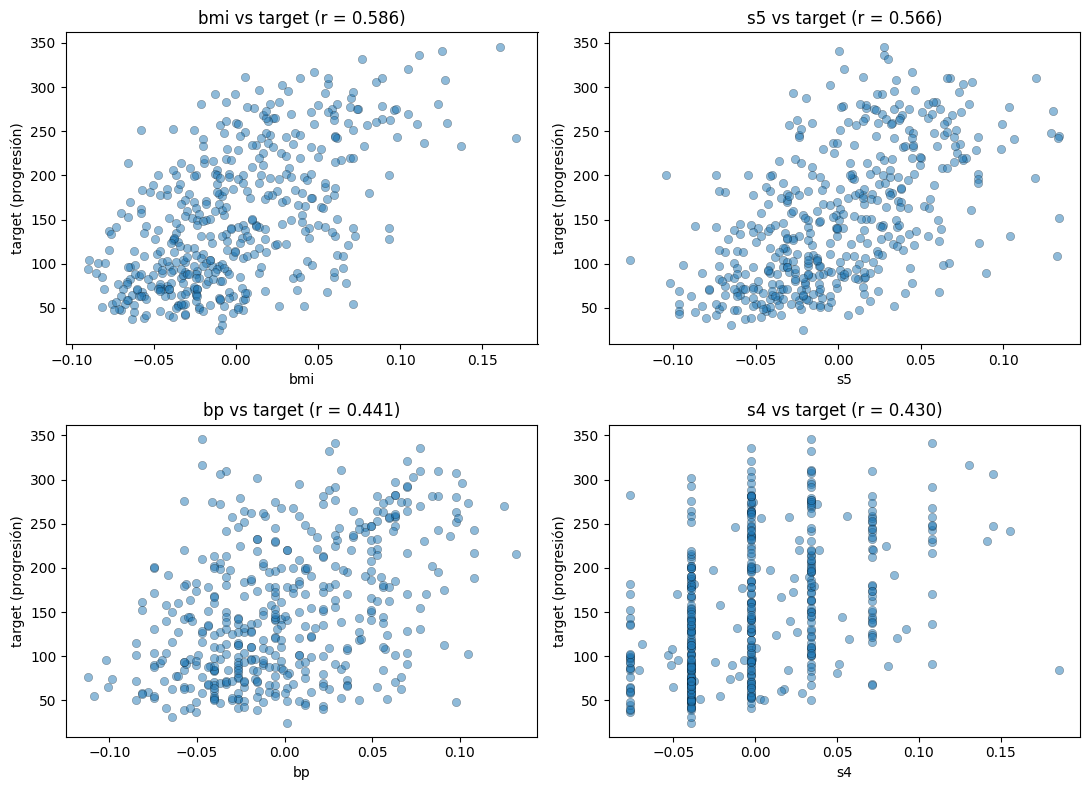

In [29]:
top4 = corr_ordenada.index[:4]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feat in zip(axes.ravel(), top4):
    ax.scatter(df[feat], df['target'], alpha=0.5, edgecolor='k', linewidth=0.3)
    ax.set_xlabel(feat)
    ax.set_ylabel('target (progresión)')
    ax.set_title(f'{feat} vs target (r = {corr[feat]:.3f})')
plt.tight_layout()
plt.show()

**5. Histograma del target**

Se visualiza la distribución del target (progresión de la enfermedad un año después del inicio) junto con su media, mediana y asimetría.

Media = 152.13 y mediana = 140.50. La media queda por encima de la mediana.
Asimetría = 0.44, es decir, asimetría positiva moderada (cola hacia la derecha).
Rango: de 25 a 346, con desviación estándar de 77.09.

El target no es perfectamente normal. Tiene una ligera cola a la derecha, porque algunos pacientes presentan una progresión mucho mayor que la típica. Aun así es razonablemente simétrico y de un solo pico, así que no hace falta transformarlo para aplicar regresión lineal.

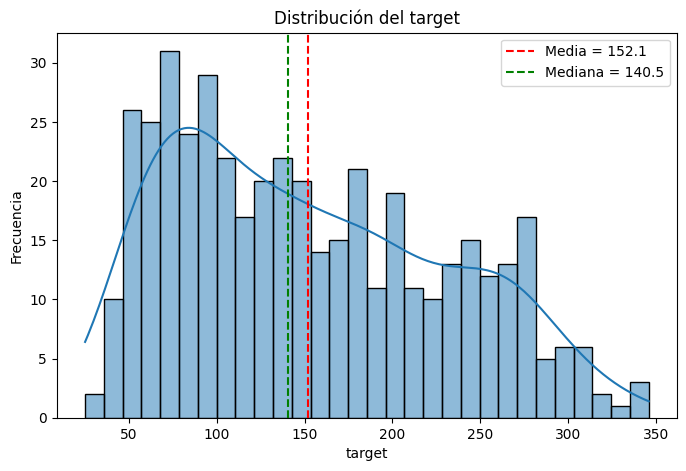

Asimetría (skewness): 0.4406


In [30]:
plt.figure(figsize=(8, 5))
sns.histplot(df['target'], bins=30, kde=True)
plt.axvline(df['target'].mean(), color='red', linestyle='--', label=f"Media = {df['target'].mean():.1f}")
plt.axvline(df['target'].median(), color='green', linestyle='--', label=f"Mediana = {df['target'].median():.1f}")
plt.xlabel('target')
plt.ylabel('Frecuencia')
plt.title('Distribución del target')
plt.legend()
plt.show()

print("Asimetría (skewness):", round(df['target'].skew(), 4))

**6. Respuesta: ¿qué features parecen más útiles?**

Los más útiles son bmi y s5, seguidos de bp y s4. Cabe destacar que s3 (-0.395) también es informativa, solo que con relación negativa; por eso conviene ordenar por valor absoluto. sex es la menos útil de forma individual.

Nota: esta conclusión solo mide relación lineal individual. Varias variables s están correlacionadas entre sí, así que su aporte conjunto puede diferir (se verá en los ejercicios 1.2 y 4.1).

In [31]:
print("Features más útiles según su correlación con el target:")
for feat in top4:
    print(f"  - {feat}: r = {corr[feat]:.3f}")

Features más útiles según su correlación con el target:
  - bmi: r = 0.586
  - s5: r = 0.566
  - bp: r = 0.441
  - s4: r = 0.430


# ***Ejercicio 1.2: Mi primera regresión lineal***

Contexto: la regresión lineal simple ajusta una recta y = b0 + b1·x con un solo feature. Aquí usamos bmi y luego comparamos con un modelo que usa los 10 features. Las métricas son RMSE (error típico, en unidades del target), MAE (error absoluto promedio) y R² (proporción de la varianza explicada).

**1. Cargar datos y dividir en train/test**

Se separa el 80% para entrenar y el 20% para evaluar.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

data = load_diabetes(as_frame=True)
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**2. Regresión lineal simple con bmi**

Se entrena el modelo usando solo la columna bmi.

In [33]:
modelo_bmi = LinearRegression()
modelo_bmi.fit(X_train[['bmi']], y_train)

print("Intercepto:", round(modelo_bmi.intercept_, 3))
print("Pendiente:", round(modelo_bmi.coef_[0], 3))

Intercepto: 152.003
Pendiente: 998.578


**3. Scatter con la recta de regresión**

Se grafican los datos de test y la recta ajustada encima.

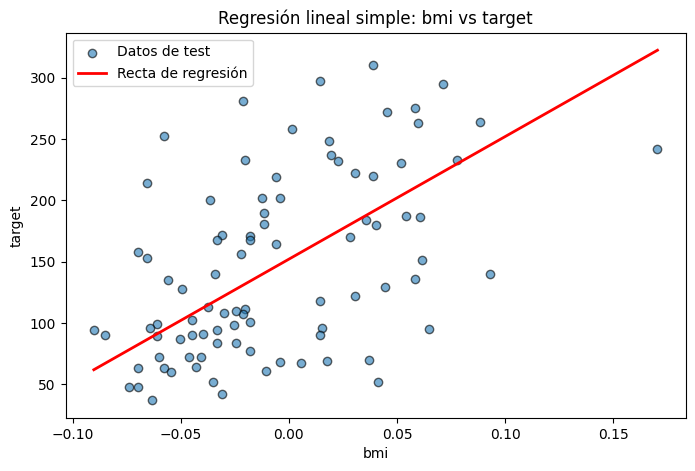

In [34]:
x_linea = np.linspace(X['bmi'].min(), X['bmi'].max(), 100).reshape(-1, 1)
y_linea = modelo_bmi.predict(pd.DataFrame(x_linea, columns=['bmi']))

plt.figure(figsize=(8, 5))
plt.scatter(X_test['bmi'], y_test, alpha=0.6, edgecolor='k', label='Datos de test')
plt.plot(x_linea, y_linea, color='red', linewidth=2, label='Recta de regresión')
plt.xlabel('bmi')
plt.ylabel('target')
plt.title('Regresión lineal simple: bmi vs target')
plt.legend()
plt.show()

**4. Métricas del modelo simple (RMSE, MAE, R²)**

Se define una función para calcular las tres métricas y se aplica al modelo con bmi.

In [35]:
def metricas(y_real, y_pred):
    return {
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
        'MAE': mean_absolute_error(y_real, y_pred),
        'R²': r2_score(y_real, y_pred)
    }

met_bmi = metricas(y_test, modelo_bmi.predict(X_test[['bmi']]))
met_bmi

{'RMSE': np.float64(63.73245584860925),
 'MAE': 52.259976445345536,
 'R²': 0.23335039815872138}

**Pendiente**= 998.58: como bmi está normalizado, 1 unidad entera no tiene sentido práctico. Mejor se interpreta por desviación estándar: 998.58 × 0.0476 ≈ 47.5. Es decir, subir 1 desviación estándar de bmi aumenta la progresión predicha en unas 47.5 unidades.

**Intercepto** = 152.00: coincide con la media del target (152.13), porque bmi está centrado en 0.

**RMSE** = 63.73: el modelo se equivoca típicamente en unos 64 puntos. Comparado con la desviación estándar del target (77.09), es una mejora pequeña sobre predecir siempre la media.

**MAE** = 52.26: el error absoluto promedio es de unos 52 puntos.

**R²** = 0.2334: bmi por sí solo explica solo el 23.3% de la variabilidad. El 76.7% restante queda sin explicar.

**5. Regresión lineal con todos los features y comparación**

Se entrena un segundo modelo con los 10 features y se arma una tabla comparativa.

In [36]:
modelo_todos = LinearRegression()
modelo_todos.fit(X_train, y_train)

met_todos = metricas(y_test, modelo_todos.predict(X_test))

tabla = pd.DataFrame({'Solo bmi': met_bmi, 'Todos los features': met_todos}).T
tabla.round(4)

,RMSE,MAE,R²
Solo bmi,63.7325,52.2600,0.2334
Todos los features,53.8534,42.7941,0.4526


**6. Respuesta: ¿cuánto mejora el R² y por qué?**

Se calcula la mejora y se escribe la explicación.

In [37]:
mejora = met_todos['R²'] - met_bmi['R²']
print(f"R² solo bmi: {met_bmi['R²']:.4f}")
print(f"R² todos:    {met_todos['R²']:.4f}")
print(f"Mejora:      {mejora:.4f}")

R² solo bmi: 0.2334
R² todos:    0.4526
Mejora:      0.2193


El R² mejora en 0.22 puntos y los errores bajan unos 9 a 10 puntos. Tiene sentido porque la progresión de la diabetes depende de varios factores a la vez (IMC, presión arterial, triglicéridos, colesterol, etc.). Con un solo feature el modelo ignora el aporte de s5, bp, s3 y otros, que según el ejercicio 1.1 también se relacionan con el target. Además, la mejora se observa en test, no solo en train, así que es una mejora real y no sobreajuste.

Limitación: incluso con todos los features, el R² es 0.45. Más de la mitad de la variabilidad sigue sin explicarse, lo que sugiere relaciones no lineales, factores no medidos o ruido. Esto motiva los modelos de los siguientes niveles.

# ***Ejercicio 1.3: Efecto del Train/Test Split***

Contexto: el resultado de un modelo depende de cómo se divide el dataset. Aquí medimos cómo cambia el R² al variar la proporción de test y la semilla aleatoria (random_state), usando California Housing (20,640 muestras, 8 features, target: valor medio de la vivienda).

**1. Cargar el dataset**

Se descarga California Housing.

In [38]:
import pandas as pd
import numpy as np

try:
    from sklearn.datasets import fetch_california_housing
    housing = fetch_california_housing(as_frame=True)
    X, y = housing.data, housing.target
    print("Cargado desde sklearn")
except Exception as e:
    print("Falló la descarga, usando sample_data de Colab:", type(e).__name__)
    raw = pd.concat([
        pd.read_csv('/content/sample_data/california_housing_train.csv'),
        pd.read_csv('/content/sample_data/california_housing_test.csv')
    ], ignore_index=True)

    X = pd.DataFrame({
        'MedInc':     raw['median_income'],
        'HouseAge':   raw['housing_median_age'],
        'AveRooms':   raw['total_rooms'] / raw['households'],
        'AveBedrms':  raw['total_bedrooms'] / raw['households'],
        'Population': raw['population'],
        'AveOccup':   raw['population'] / raw['households'],
        'Latitude':   raw['latitude'],
        'Longitude':  raw['longitude'],
    })
    y = (raw['median_house_value'] / 100000).rename('MedHouseVal')

print(X.shape)
X.head()

/usr/local/lib/python3.13/dist-packages/sklearn/datasets/_base.py:1519: UserWarning: Retry downloading from url: https://ndownloader.figshare.com/files/5976036
  warnings.warn(f"Retry downloading from url: {remote.url}")


Falló la descarga, usando sample_data de Colab: HTTPError
(20000, 8)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,1.4936,15.0,11.889831,2.718220,1015.0,2.150424,34.19,-114.31
1,1.8200,19.0,16.522678,4.105832,1129.0,2.438445,34.40,-114.47
2,1.6509,17.0,6.153846,1.487179,333.0,2.846154,33.69,-114.56
3,3.1917,14.0,6.641593,1.491150,515.0,2.278761,33.64,-114.57
4,1.9250,20.0,5.549618,1.244275,624.0,2.381679,33.57,-114.57


**2. Regresión lineal con 4 proporciones de test**

Se entrena con test de 10%, 20%, 30% y 50%, y se reporta R² en train y test.

In [39]:
resultados_size = []
for ts in [0.10, 0.20, 0.30, 0.50]:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=ts, random_state=42)
    lr = LinearRegression().fit(X_tr, y_tr)
    resultados_size.append({
        'test_size': ts,
        'n_train': len(X_tr),
        'R² train': r2_score(y_tr, lr.predict(X_tr)),
        'R² test': r2_score(y_te, lr.predict(X_te))
    })

tabla_size = pd.DataFrame(resultados_size)
tabla_size.round(4)

,test_size,n_train,R² train,R² test
0,0.1,18000,0.6044,0.6388
1,0.2,16000,0.6067,0.6121
2,0.3,14000,0.6078,0.6049
3,0.5,10000,0.6109,0.6020


**3. Variar el random_state (test_size = 0.2)**

Se repite el entrenamiento con semillas 0, 7, 42 y 99, y se reporta el R².

In [40]:
resultados_seed = []
for rs in [0, 7, 42, 99]:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=rs)
    lr = LinearRegression().fit(X_tr, y_tr)
    resultados_seed.append({
        'random_state': rs,
        'R² train': r2_score(y_tr, lr.predict(X_tr)),
        'R² test': r2_score(y_te, lr.predict(X_te))
    })

tabla_seed = pd.DataFrame(resultados_seed)
tabla_seed.round(4)

,random_state,R² train,R² test
0,0,0.6146,0.5243
1,7,0.6096,0.6003
2,42,0.6067,0.6121
3,99,0.6115,0.5903


R² train casi no cambia: 0.6044 → 0.6109. Sube muy poco al reducirse el train, porque con menos datos es un poco más fácil ajustarlos.
R² test baja: 0.6388 (test 10%) → 0.6020 (test 50%).
Cuidado al interpretarlo: con test de 10% la evaluación se hace sobre solo 2,000 filas, y ese 0.6388 puede ser en parte suerte de la muestra. No es evidencia de que “menos test sea mejor”.

**4. Desviación estándar de los R² entre semillas**

Se mide cuánta variación introduce solo el azar de la división.

In [41]:
std_test = tabla_seed['R² test'].std()
std_train = tabla_seed['R² train'].std()

print(f"Desv. estándar R² test:  {std_test:.5f}")
print(f"Desv. estándar R² train: {std_train:.5f}")

Desv. estándar R² test:  0.03934
Desv. estándar R² train: 0.00334


**Test:** 0.03934

**Train:** 0.00334

El R² de test varía unas 12 veces más que el de train (0.03934 / 0.00334 ≈ 11.8). Esto ocurre porque train usa 16,000 filas y promedia el azar, mientras que test usa solo 4,000 y es mucho más sensible a qué casos difíciles o atípicos le tocaron.

**5. Respuesta: ¿por qué varían los resultados y qué técnica lo resuelve?**

Los resultados varían porque cada random_state produce una partición distinta. Con la semilla 0 el test recibió más casos difíciles (R² = 0.524) y con la 42 recibió casos más fáciles (R² = 0.612). Alguien que eligiera solo la semilla 42 reportaría un modelo mejor de lo que realmente es. Por eso un único split no es confiable. La técnica que resuelve esto es la validación cruzada (k-fold): evalúa el modelo en varias particiones y promedia, dando una estimación más estable. Con 5 folds se obtuvo R² medio de 0.5700 (desviación 0.0656), con valores entre 0.4797 y 0.6562.

In [42]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring='r2')
print("R² por fold:", scores.round(4))
print(f"Media: {scores.mean():.4f} | Desv. estándar: {scores.std():.4f}")

R² por fold: [0.5938 0.4797 0.5092 0.6562 0.6112]
Media: 0.5700 | Desv. estándar: 0.0656


# ***Ejercicio 2.1: Regresión polinomial, grado óptimo***

Contexto: un modelo muy simple no capta la curvatura (underfitting, sesgo alto) y uno muy complejo memoriza el ruido (overfitting, varianza alta). Probamos grados 1 a 15 sobre datos de una parábola con ruido y buscamos el punto donde el error de test es mínimo.

**1. Generar los datos**

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

np.random.seed(42)
Xs = np.random.uniform(-3, 3, 100).reshape(-1, 1)
ys = 3*Xs.ravel()**2 - 2*Xs.ravel() + 5 + np.random.normal(0, 3, 100)

**2. Dividir en train/test (80/20)**

In [44]:
Xs_train, Xs_test, ys_train, ys_test = train_test_split(Xs, ys, test_size=0.2, random_state=42)
print(Xs_train.shape, Xs_test.shape)

(80, 1) (20, 1)


**3. Entrenar grados 1 a 15**

Cada modelo es un pipeline: se generan las potencias de x, se estandarizan (evita problemas numéricos con x¹⁵) y se ajusta una regresión lineal.

In [45]:
def rmse(y_real, y_pred):
    return np.sqrt(mean_squared_error(y_real, y_pred))

filas = []
for g in range(1, 16):
    modelo = make_pipeline(PolynomialFeatures(g, include_bias=False),
                           StandardScaler(), LinearRegression())
    modelo.fit(Xs_train, ys_train)
    filas.append({'grado': g,
                  'RMSE train': rmse(ys_train, modelo.predict(Xs_train)),
                  'RMSE test':  rmse(ys_test,  modelo.predict(Xs_test))})

tabla_pol = pd.DataFrame(filas).set_index('grado')
tabla_pol.round(3)

,RMSE train,RMSE test
grado,,
1,9.057,8.214
2,2.708,2.392
3,2.696,2.404
4,2.662,2.490
5,2.659,2.485
6,2.654,2.515
7,2.653,2.528
8,2.653,2.529
9,2.647,2.493


**4. Graficar Train RMSE y Test RMSE vs. grado**

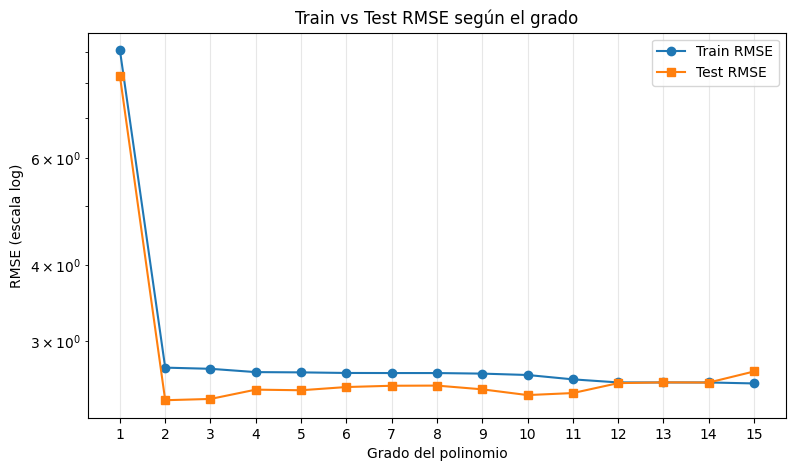

In [46]:
plt.figure(figsize=(9, 5))
plt.plot(tabla_pol.index, tabla_pol['RMSE train'], 'o-', label='Train RMSE')
plt.plot(tabla_pol.index, tabla_pol['RMSE test'], 's-', label='Test RMSE')
plt.yscale('log')   # el test puede dispararse en grados altos
plt.xlabel('Grado del polinomio')
plt.ylabel('RMSE (escala log)')
plt.title('Train vs Test RMSE según el grado')
plt.xticks(range(1, 16))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**5. Grado óptimo y zonas de underfitting/overfitting**

El grado óptimo es el que minimiza el RMSE de test. A la izquierda queda el underfitting y a la derecha el overfitting.

Grado óptimo: 2
RMSE test en el óptimo: 2.392


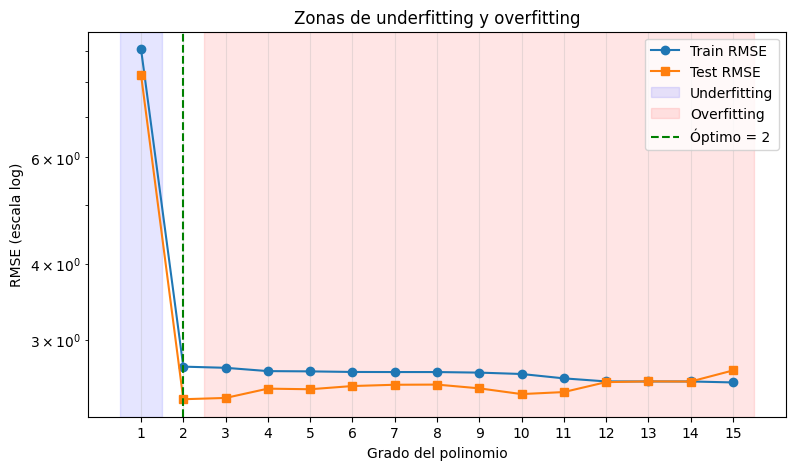

In [47]:
grado_opt = int(tabla_pol['RMSE test'].idxmin())
print("Grado óptimo:", grado_opt)
print("RMSE test en el óptimo:", round(tabla_pol.loc[grado_opt, 'RMSE test'], 3))

plt.figure(figsize=(9, 5))
plt.plot(tabla_pol.index, tabla_pol['RMSE train'], 'o-', label='Train RMSE')
plt.plot(tabla_pol.index, tabla_pol['RMSE test'], 's-', label='Test RMSE')
if grado_opt > 1:
    plt.axvspan(0.5, grado_opt - 0.5, color='blue', alpha=0.1, label='Underfitting')
plt.axvspan(grado_opt + 0.5, 15.5, color='red', alpha=0.1, label='Overfitting')
plt.axvline(grado_opt, color='green', linestyle='--', label=f'Óptimo = {grado_opt}')
plt.yscale('log')
plt.xlabel('Grado del polinomio')
plt.ylabel('RMSE (escala log)')
plt.title('Zonas de underfitting y overfitting')
plt.xticks(range(1, 16))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**6. Curvas de los modelos con grado 1, óptimo y 15**

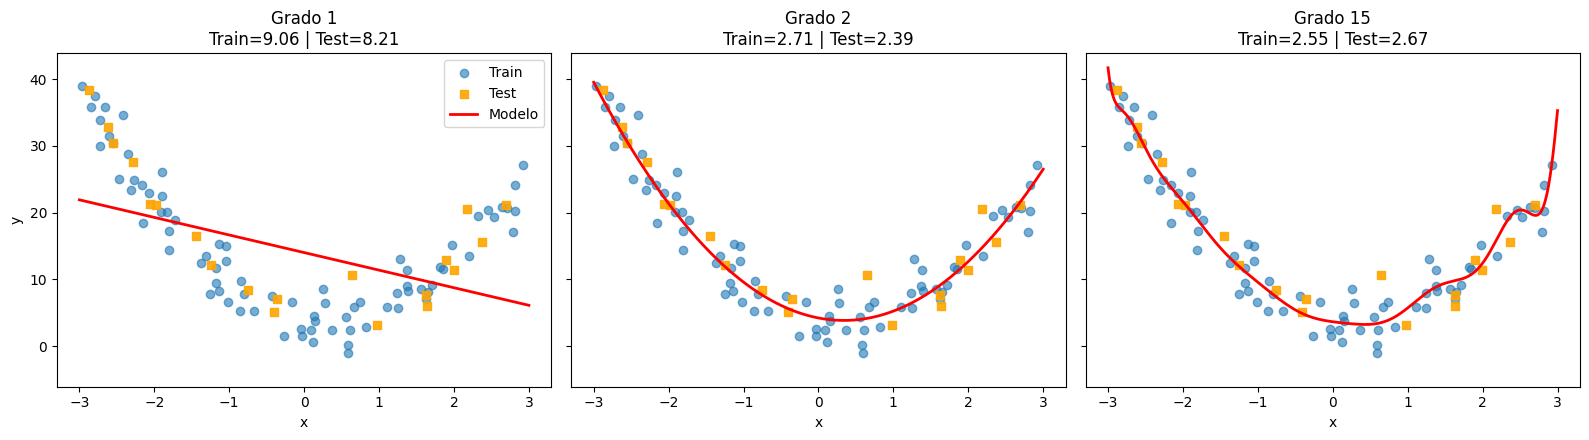

In [48]:
x_grid = np.linspace(-3, 3, 300).reshape(-1, 1)
grados_plot = [1, grado_opt, 15]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, g in zip(axes, grados_plot):
    modelo = make_pipeline(PolynomialFeatures(g, include_bias=False),
                           StandardScaler(), LinearRegression()).fit(Xs_train, ys_train)
    ax.scatter(Xs_train, ys_train, alpha=0.6, label='Train')
    ax.scatter(Xs_test, ys_test, alpha=0.9, marker='s', color='orange', label='Test')
    ax.plot(x_grid, modelo.predict(x_grid), color='red', linewidth=2, label='Modelo')
    ax.set_ylim(ys.min() - 5, ys.max() + 5)
    ax.set_title(f"Grado {g}\nTrain={tabla_pol.loc[g,'RMSE train']:.2f} | Test={tabla_pol.loc[g,'RMSE test']:.2f}")
    ax.set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].legend()
plt.tight_layout()
plt.show()

**Celda común para los ejercicios 2.2, 2.3 y 2.4 (California Housing)**

Si tu sesión sigue activa, X e y de California Housing ya existen, pero el 2.1 no los tocó gracias a los nombres Xs, ys. Aun así, esta celda los recarga y crea el split que usarán los tres ejercicios.

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

try:
    from sklearn.datasets import fetch_california_housing
    housing = fetch_california_housing(as_frame=True)
    X, y = housing.data, housing.target
    print("Cargado desde sklearn")
except Exception as e:
    print("Descarga falló, usando sample_data:", type(e).__name__)
    raw = pd.concat([
        pd.read_csv('/content/sample_data/california_housing_train.csv'),
        pd.read_csv('/content/sample_data/california_housing_test.csv')
    ], ignore_index=True)
    X = pd.DataFrame({
        'MedInc': raw['median_income'], 'HouseAge': raw['housing_median_age'],
        'AveRooms': raw['total_rooms']/raw['households'],
        'AveBedrms': raw['total_bedrooms']/raw['households'],
        'Population': raw['population'],
        'AveOccup': raw['population']/raw['households'],
        'Latitude': raw['latitude'], 'Longitude': raw['longitude']})
    y = (raw['median_house_value']/100000).rename('MedHouseVal')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X.shape, X_train.shape, X_test.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/datasets/_base.py:1519: UserWarning: Retry downloading from url: https://ndownloader.figshare.com/files/5976036
  warnings.warn(f"Retry downloading from url: {remote.url}")


Descarga falló, usando sample_data: HTTPError
(20000, 8) (16000, 8) (4000, 8)


# ***Ejercicio 2.2: Comparación Ridge vs Lasso***

Contexto: ambos son regresión lineal con regularización, que penaliza coeficientes grandes. Ridge usa la penalización L2 (encoge los coeficientes) y Lasso usa L1 (puede llevarlos exactamente a cero). Estandarizamos antes porque la penalización depende de la escala de cada feature.

**1. Pipelines con StandardScaler**

In [50]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso

alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
modelos = {
    'Ridge': lambda a: make_pipeline(StandardScaler(), Ridge(alpha=a)),
    'Lasso': lambda a: make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=10000))
}

**2 y 3. Probar cada alpha: R² en test y coeficientes distintos de cero**

In [51]:
resultados = []
coefs = {'Ridge': [], 'Lasso': []}

for nombre, fabrica in modelos.items():
    for a in alphas:
        pipe = fabrica(a).fit(X_train, y_train)
        coef = pipe[-1].coef_
        coefs[nombre].append(coef)
        resultados.append({
            'modelo': nombre,
            'alpha': a,
            'R² test': r2_score(y_test, pipe.predict(X_test)),
            'Coef ≠ 0': int(np.sum(coef != 0))
        })

tabla_rl = pd.DataFrame(resultados)
tabla_rl.pivot(index='alpha', columns='modelo', values=['R² test', 'Coef ≠ 0']).round(4)

R² test         Coef ≠ 0      
modelo    Lasso   Ridge    Lasso Ridge
alpha                                 
0.001    0.6121  0.6121      8.0   8.0
0.010    0.6083  0.6121      7.0   8.0
0.100    0.5021  0.6121      3.0   8.0
1.000   -0.0000  0.6121      0.0   8.0
10.000  -0.0000  0.6121      0.0   8.0
100.000 -0.0000  0.6116      0.0   8.0

**4. R² vs alpha (Ridge y Lasso en el mismo gráfico)**

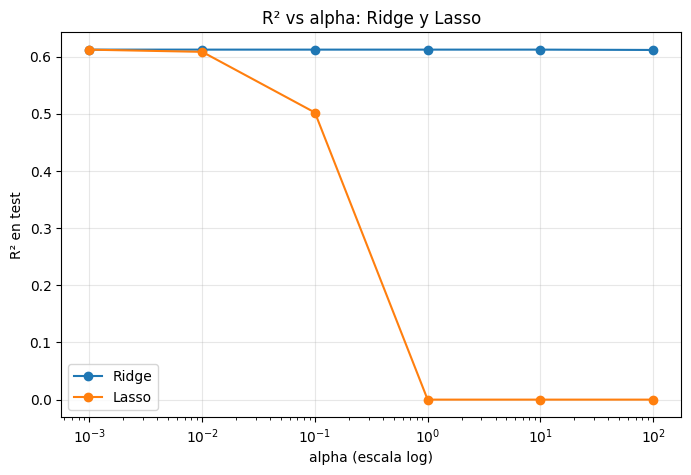

In [52]:
plt.figure(figsize=(8, 5))
for nombre in ['Ridge', 'Lasso']:
    sub = tabla_rl[tabla_rl['modelo'] == nombre]
    plt.plot(sub['alpha'], sub['R² test'], 'o-', label=nombre)
plt.xscale('log')
plt.xlabel('alpha (escala log)')
plt.ylabel('R² en test')
plt.title('R² vs alpha: Ridge y Lasso')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**5. Evolución de los coeficientes vs alpha (un gráfico por modelo)**

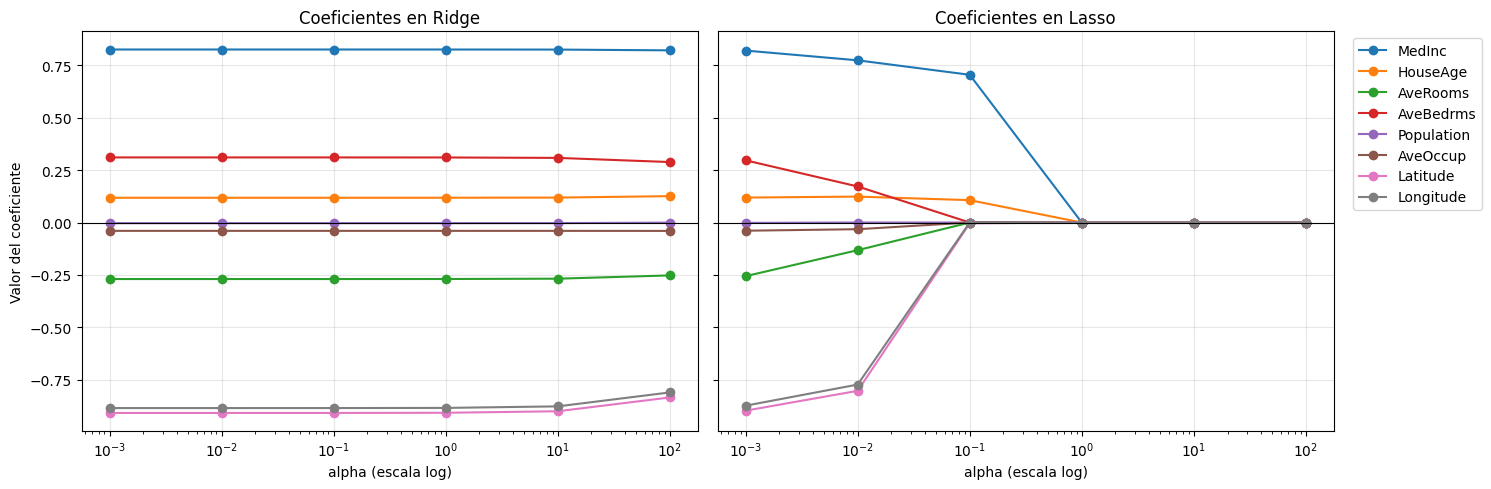

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, nombre in zip(axes, ['Ridge', 'Lasso']):
    matriz = np.array(coefs[nombre])          # filas = alphas, columnas = features
    for j, feat in enumerate(X.columns):
        ax.plot(alphas, matriz[:, j], 'o-', label=feat)
    ax.set_xscale('log')
    ax.set_xlabel('alpha (escala log)')
    ax.set_title(f'Coeficientes en {nombre}')
    ax.axhline(0, color='k', linewidth=0.8)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Valor del coeficiente')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# ***Ejercicio 2.3: Árbol de decisión para regresión***

Contexto: un árbol divide los datos con preguntas sucesivas. max_depth controla su complejidad: poca profundidad da underfitting, demasiada memoriza el train (overfitting).

**1 y 2. Entrenar con max_depth de 1 a 20 y registrar R²**

In [54]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

filas = []
for d in range(1, 21):
    arbol = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train, y_train)
    filas.append({'max_depth': d,
                  'R² train': r2_score(y_train, arbol.predict(X_train)),
                  'R² test':  r2_score(y_test,  arbol.predict(X_test))})

tabla_arbol = pd.DataFrame(filas).set_index('max_depth')
tabla_arbol.round(4)

,R² train,R² test
max_depth,,
1,0.3107,0.3069
2,0.4474,0.4490
3,0.5332,0.5417
4,0.5838,0.5892
5,0.6332,0.6235
6,0.6698,0.6542
7,0.7133,0.6781
8,0.7577,0.7000
9,0.7967,0.7145


**3. Graficar ambas curvas e identificar el overfitting**

El punto de overfitting es donde el R² de test deja de mejorar (alcanza su máximo) mientras el de train sigue subiendo.

Profundidad óptima: 9 | R² test: 0.7145


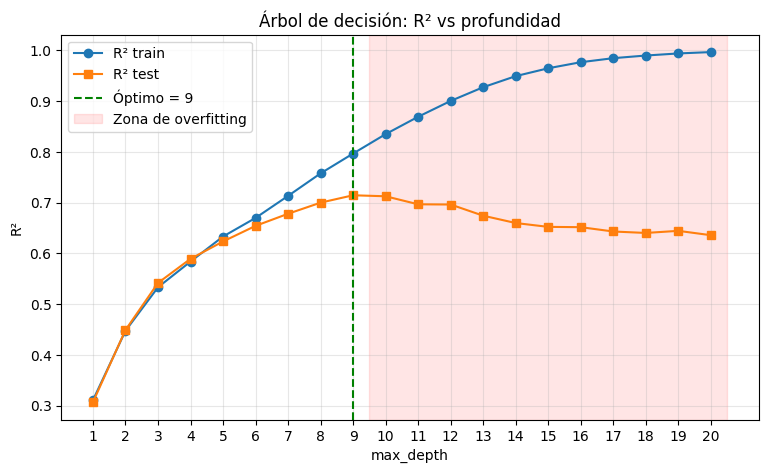

In [55]:
prof_opt = int(tabla_arbol['R² test'].idxmax())
print("Profundidad óptima:", prof_opt, "| R² test:", round(tabla_arbol.loc[prof_opt, 'R² test'], 4))

plt.figure(figsize=(9, 5))
plt.plot(tabla_arbol.index, tabla_arbol['R² train'], 'o-', label='R² train')
plt.plot(tabla_arbol.index, tabla_arbol['R² test'], 's-', label='R² test')
plt.axvline(prof_opt, color='green', linestyle='--', label=f'Óptimo = {prof_opt}')
plt.axvspan(prof_opt + 0.5, 20.5, color='red', alpha=0.1, label='Zona de overfitting')
plt.xlabel('max_depth')
plt.ylabel('R²')
plt.title('Árbol de decisión: R² vs profundidad')
plt.xticks(range(1, 21))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**4. Visualizar el árbol óptimo (hasta 3 niveles)**

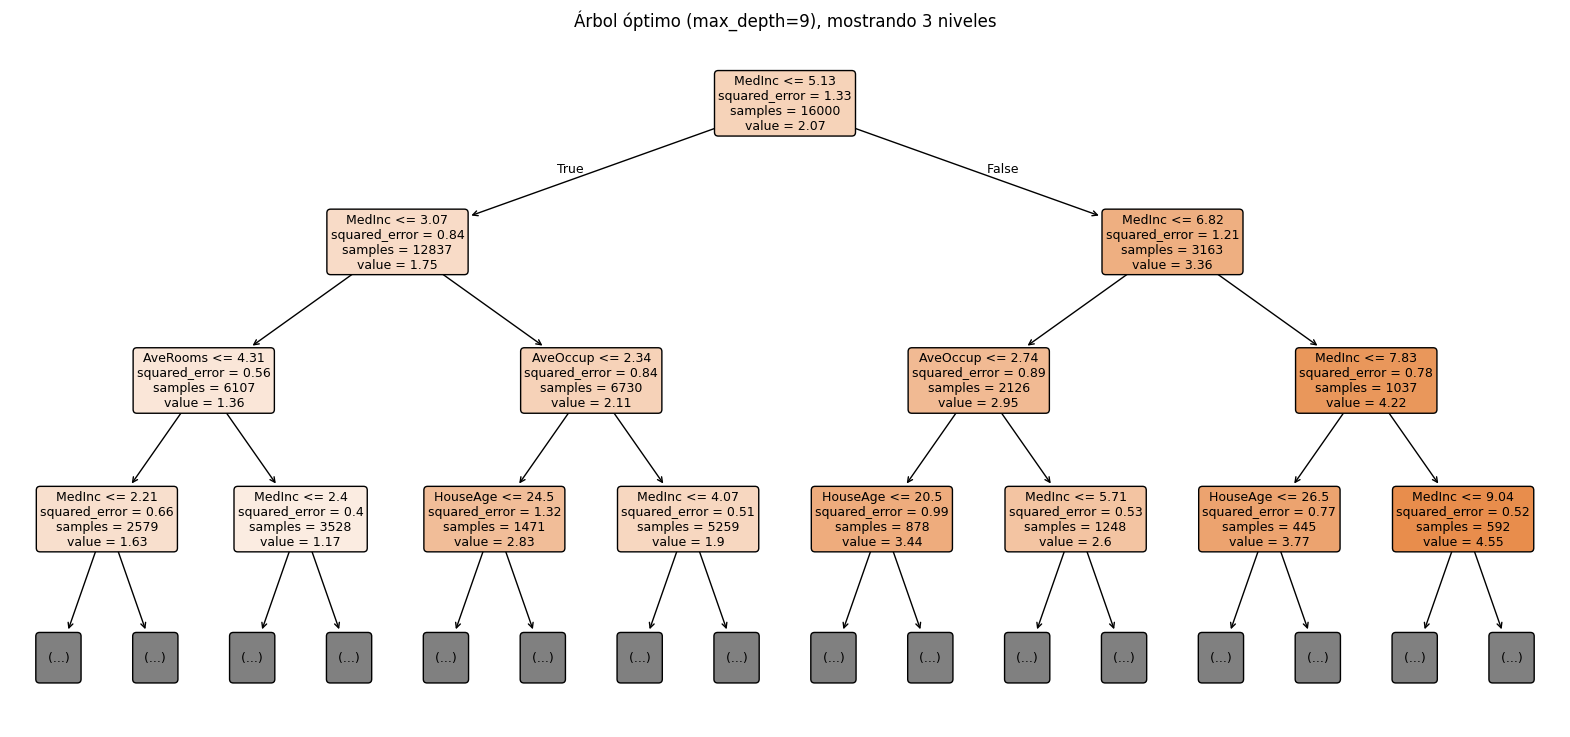

In [56]:
arbol_opt = DecisionTreeRegressor(max_depth=prof_opt, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(20, 9))
plot_tree(arbol_opt, max_depth=3, feature_names=X.columns, filled=True,
          rounded=True, fontsize=9, precision=2)
plt.title(f'Árbol óptimo (max_depth={prof_opt}), mostrando 3 niveles')
plt.show()

**5. Importancia de features (barras horizontales)**

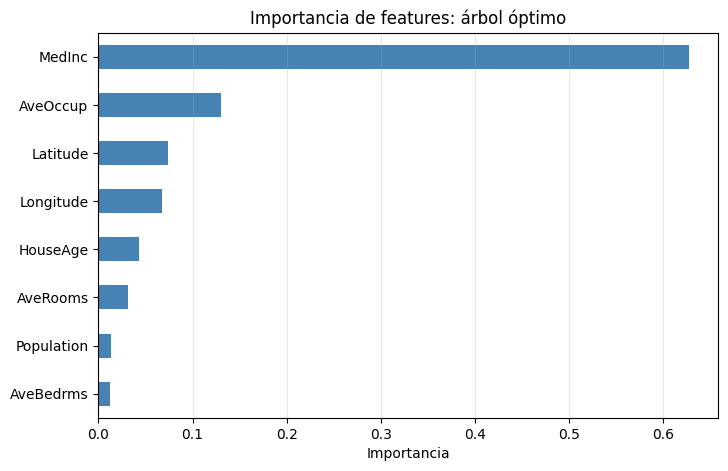

MedInc        0.6270
AveOccup      0.1304
Latitude      0.0744
Longitude     0.0678
HouseAge      0.0429
AveRooms      0.0312
Population    0.0134
AveBedrms     0.0128
dtype: float64


In [57]:
imp = pd.Series(arbol_opt.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
imp.plot(kind='barh', color='steelblue')
plt.xlabel('Importancia')
plt.title('Importancia de features: árbol óptimo')
plt.grid(axis='x', alpha=0.3)
plt.show()
print(imp.sort_values(ascending=False).round(4))

**6. Comparar con la regresión lineal**

In [58]:
lr = LinearRegression().fit(X_train, y_train)
r2_lr = r2_score(y_test, lr.predict(X_test))
r2_arbol = r2_score(y_test, arbol_opt.predict(X_test))

comp = pd.DataFrame({'R² test': {'Regresión lineal': r2_lr,
                                 f'Árbol (depth={prof_opt})': r2_arbol}})
comp['Diferencia vs lineal'] = comp['R² test'] - r2_lr
comp.round(4)

,R² test,Diferencia vs lineal
Regresión lineal,0.6121,0.0000
Árbol (depth=9),0.7145,0.1023


# ***Ejercicio 2.4: Random Forest, número de árboles y profundidad***

Contexto: un Random Forest promedia muchos árboles entrenados con muestras y features aleatorios, lo que reduce la varianza. Exploramos dos hiperparámetros: n_estimators (cuántos árboles) y max_depth (qué tan profundos).

**1 y 2. Fijar max_depth=10 y variar n_estimators**

   n_estimators  R² test
0             1   0.6871
1             5   0.7693
2            10   0.7824
3            25   0.7877
4            50   0.7881
5           100   0.7900
6           200   0.7907
7           500   0.7919


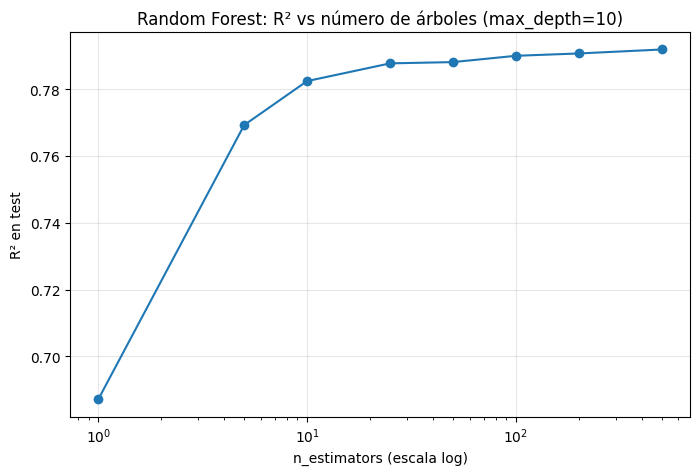

In [59]:
from sklearn.ensemble import RandomForestRegressor

n_list = [1, 5, 10, 25, 50, 100, 200, 500]
r2_n = []
for n in n_list:
    rf = RandomForestRegressor(n_estimators=n, max_depth=10, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    r2_n.append(r2_score(y_test, rf.predict(X_test)))

tabla_n = pd.DataFrame({'n_estimators': n_list, 'R² test': r2_n})
print(tabla_n.round(4))

plt.figure(figsize=(8, 5))
plt.plot(n_list, r2_n, 'o-')
plt.xscale('log')
plt.xlabel('n_estimators (escala log)')
plt.ylabel('R² en test')
plt.title('Random Forest: R² vs número de árboles (max_depth=10)')
plt.grid(alpha=0.3)
plt.show()

**3 y 4. Fijar n_estimators=100 y variar max_depth**

  max_depth  R² test
0         2   0.4637
1         4   0.6283
2         6   0.7077
3         8   0.7595
4        10   0.7900
5        12   0.8057
6        15   0.8148
7      None   0.8183


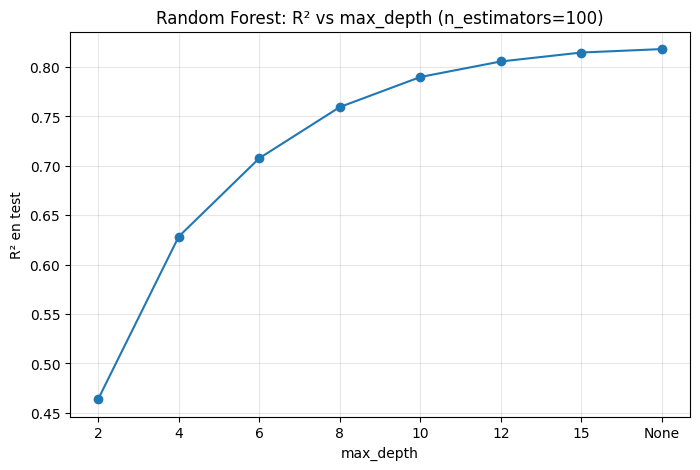

In [60]:
d_list = [2, 4, 6, 8, 10, 12, 15, None]
r2_d = []
for d in d_list:
    rf = RandomForestRegressor(n_estimators=100, max_depth=d, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    r2_d.append(r2_score(y_test, rf.predict(X_test)))

etiquetas = [str(d) for d in d_list]
tabla_d = pd.DataFrame({'max_depth': etiquetas, 'R² test': r2_d})
print(tabla_d.round(4))

plt.figure(figsize=(8, 5))
plt.plot(etiquetas, r2_d, 'o-')
plt.xlabel('max_depth')
plt.ylabel('R² en test')
plt.title('Random Forest: R² vs max_depth (n_estimators=100)')
plt.grid(alpha=0.3)
plt.show()

**5. Entrenar con la combinación óptima**

Se toma el mejor n_estimators y el mejor max_depth de los dos experimentos anteriores.

In [61]:
mejor_n = n_list[int(np.argmax(r2_n))]
mejor_d = d_list[int(np.argmax(r2_d))]
print("Mejor n_estimators:", mejor_n, "| Mejor max_depth:", mejor_d)

rf_final = RandomForestRegressor(n_estimators=mejor_n, max_depth=mejor_d,
                                 random_state=42, n_jobs=-1).fit(X_train, y_train)

print("R² train:", round(r2_score(y_train, rf_final.predict(X_train)), 4))
print("R² test: ", round(r2_score(y_test,  rf_final.predict(X_test)), 4))

Mejor n_estimators: 500 | Mejor max_depth: None
R² train: 0.9745
R² test:  0.8212
